<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and provenance](README.md)

# 01 · Read static evidence without turning it into a verdict

**Which observations describe a file, and which depend on how we extract them?**
We will inspect committed hello-world binaries in PE, ELF and Mach-O formats,
contrast whole-file and section entropy, and vary a printable-string extractor's
minimum length. An unrecognized text fixture, empty bytes and missing input remain
in the audit.

VGI PE uses LIEF to read local bytes. None of the binaries is executed, loaded as a
library or allowed to resolve imports. These benign fixtures are not a malware
benchmark. Entropy, a signature-presence flag and readable strings alone establish
neither maliciousness nor trust.

## Choose the printable-string minimum

`MIN_STRING_LENGTH=8` is the saved default. The experiment raises it to `16`, which
changes extraction granularity while leaving the file bytes and scalar evidence
fixed. The notebook compares the result with a fixed eight-character baseline.
Use an integer from 8 to 64; restart and run all after changing it.

In [1]:
MIN_STRING_LENGTH = 8

In [2]:
import os

os.environ["PLOOMBER_STATS_ENABLED"] = "false"
import math
from collections import Counter
from pathlib import Path
import haybarn
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from notebook_support import finish, prose, theme

if type(MIN_STRING_LENGTH) is not int or not 8 <= MIN_STRING_LENGTH <= 64:
    raise ValueError("MIN_STRING_LENGTH must be an integer from 8 to 64.")
evidence = retention = checks = pd.DataFrame()
theme()
con = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-pe/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-pe/notebooks/pyproject.toml.

## Attach the pinned public Git worker

The literal `uvx` location fetches the remotely available v0.4.0 commit and uses
explicit SDK, transport, Arrow and LIEF versions. It does not require this worker
checkout. The notebook environment and worker environment are separate. First use
needs Git/network access and compatible wheels; analysis itself is local.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'pe' (TYPE vgi,LOCATION 'uvx --python 3.14 --with vgi-python==0.51.0 --with vgi-rpc==0.53.1 --with pyarrow==26.0.1 --with lief==1.0.0 --from git+https://github.com/Query-farm/vgi-pe@473ecf09bded3b87ee672aab3bf36903d635563d vgi-pe-worker');
SELECT name,kind,formats FROM pe.main.analyses ORDER BY kind,name;

,name,kind,formats
0,binary_format,scalar,"PE, ELF, Mach-O"
1,compile_timestamp,scalar,PE only
2,entry_point,scalar,"PE, ELF, Mach-O"
3,imphash,scalar,PE only
4,is_signed,scalar,"PE, Mach-O"
5,machine,scalar,"PE, ELF, Mach-O"
6,overall_entropy,scalar,"PE, ELF, Mach-O"
7,section_count,scalar,"PE, ELF, Mach-O"
8,exports,table,"PE, ELF, Mach-O"
9,imports,table,"PE, ELF, Mach-O"


## Audit bytes before interpreting format-specific fields

The three executable fixtures are unchanged outputs of the repository's tiny C
hello-world program. `garbage.bin` is authored text with some nonprintable bytes;
`empty.bin` has zero bytes, and the missing row has SQL NULL. The input manifest
records SHA-256 hashes and provenance. No compiler is needed to read them.

Scalar calls take the BLOB column directly. The whole-file hash identifies input
bytes; the PE import hash describes an ordered import table and is a different
object. `compile_timestamp` is PE header metadata, not proof of actual build time;
this fixture deliberately has a fixed timestamp.

In [4]:
%%sql
CREATE TABLE samples AS SELECT regexp_extract(filename,'([^/]+)$',1) AS sample_id,
 filename AS source_path,content AS bytes
FROM read_blob(['fixtures/hello.exe','fixtures/hello_elf','fixtures/hello_macho','fixtures/garbage.bin','fixtures/empty.bin'])
UNION ALL SELECT 'missing',NULL,NULL::BLOB;
CREATE TABLE binary_audit AS SELECT *,octet_length(bytes) AS file_bytes,sha256(bytes) AS file_sha256,
 pe.main.binary_format(bytes) AS format,pe.main.machine(bytes) AS machine,
 pe.main.is_signed(bytes) AS signature_present,pe.main.compile_timestamp(bytes) AS pe_header_timestamp,
 pe.main.imphash(bytes) AS pe_import_hash,pe.main.overall_entropy(bytes) AS file_entropy,
 pe.main.section_count(bytes) AS reported_sections
FROM samples;
SELECT sample_id,file_bytes,format,machine,signature_present,pe_header_timestamp,
 pe_import_hash,reported_sections,file_entropy FROM binary_audit ORDER BY sample_id;

,sample_id,file_bytes,format,machine,signature_present,pe_header_timestamp,pe_import_hash,reported_sections,file_entropy
0,empty.bin,0,None,None,<NA>,NaT,None,<NA>,NaN
1,garbage.bin,212,None,None,<NA>,NaT,None,<NA>,NaN
2,hello.exe,142249,PE,X86_64,False,2023-11-14 22:13:20,7ff113ca9631a5215fdc9b66c067ad8f,18,5.443705
3,hello_elf,5232,ELF,X86_64,False,NaT,None,9,5.560807
4,hello_macho,33432,MachO,ARM64,True,NaT,None,5,0.338222
5,missing,<NA>,None,None,<NA>,NaT,None,<NA>,NaN


## Compare whole-file and section evidence

The worker computes whole-file entropy over the bytes, but reports it only when
LIEF recognizes a binary. NULL for the text fixture means the API did not report
that metric; it does not mean the text has zero entropy. Missing and empty inputs
remain distinguishable through byte count.

Section entropy describes a different byte population. File headers, padding and
layout affect whole-file entropy, so it is not the average of section scores.
The maximum section value is a descriptive comparison, not a detection threshold.
The section `characteristics` field is PE-specific; an empty field for ELF/Mach-O
is not evidence that those formats lack section permissions.

In [5]:
%%sql
CREATE TABLE section_rows AS
SELECT 'hello.exe' AS sample_id,* FROM pe.main.sections('fixtures/hello.exe')
UNION ALL
SELECT 'hello_elf' AS sample_id,* FROM pe.main.sections('fixtures/hello_elf')
UNION ALL
SELECT 'hello_macho' AS sample_id,* FROM pe.main.sections('fixtures/hello_macho')
UNION ALL
SELECT 'garbage.bin' AS sample_id,* FROM pe.main.sections('fixtures/garbage.bin')
UNION ALL
SELECT 'empty.bin' AS sample_id,* FROM pe.main.sections('fixtures/empty.bin');
SELECT sample_id,name,virtual_size,raw_size,entropy,characteristics FROM section_rows
ORDER BY sample_id,entropy DESC,name;

,sample_id,name,virtual_size,raw_size,entropy,characteristics
0,hello.exe,.text,6640,6656,5.969688,"CNT_CODE,MEM_EXECUTE,MEM_READ"
1,hello.exe,/19,49451,49664,5.937540,"MEM_READ,MEM_DISCARDABLE"
2,hello.exe,/97,5537,5632,5.168436,"MEM_READ,MEM_DISCARDABLE"
3,hello.exe,/70,914,1024,5.112117,"MEM_READ,MEM_DISCARDABLE"
4,hello.exe,/45,8168,8192,4.943037,"MEM_READ,MEM_DISCARDABLE"
5,hello.exe,/31,8358,8704,4.830922,"MEM_READ,MEM_DISCARDABLE"
6,hello.exe,/81,9698,9728,4.827193,"MEM_READ,MEM_DISCARDABLE"
7,hello.exe,/113,360,512,4.648213,"MEM_READ,MEM_DISCARDABLE"
8,hello.exe,/57,2192,2560,4.132195,"MEM_READ,MEM_DISCARDABLE"
9,hello.exe,.rdata,2552,2560,4.075373,MEM_READ


In [6]:
%%sql evidence <<
SELECT a.sample_id,a.format,a.file_bytes,a.file_entropy,a.signature_present,a.reported_sections,
 count(s.sample_id) AS extracted_sections,max(s.entropy) AS highest_section_entropy
FROM binary_audit a LEFT JOIN section_rows s USING(sample_id)
GROUP BY ALL ORDER BY a.sample_id;

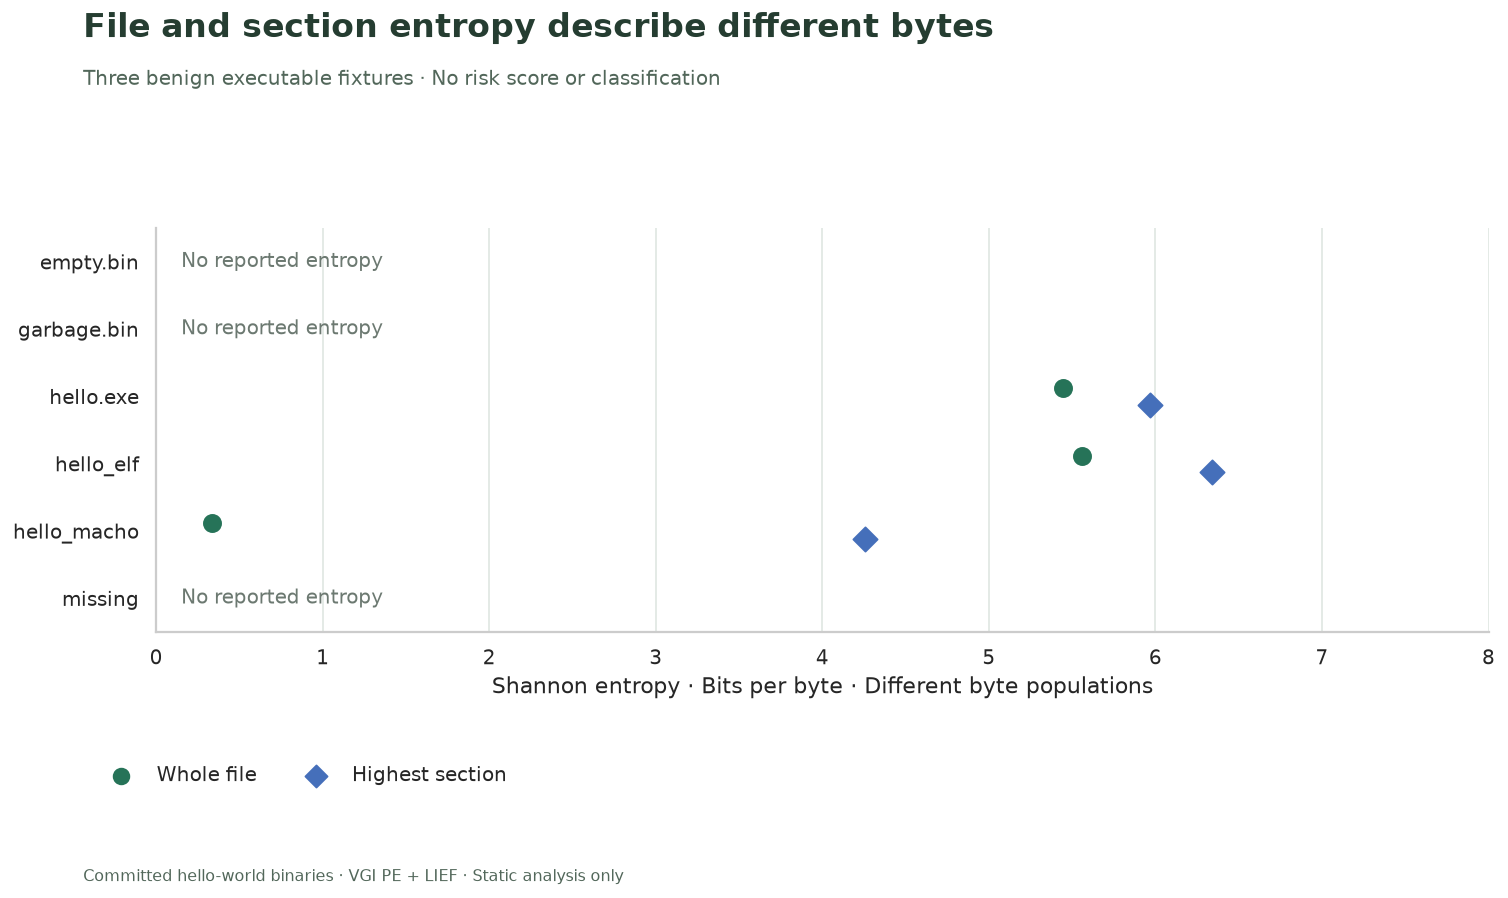

**3 of 6 inputs** have a recognized executable format. The Mach-O fixture has a signature-presence flag, which does not verify its signature or establish signer trust. The ELF false result reflects this worker’s embedded-signature convention; it is not a cross-format trust verdict.

In [7]:
fig, ax = plt.subplots(figsize=(12, 7))
for y, r in enumerate(evidence.itertuples()):
    if pd.isna(r.file_entropy):
        ax.text(0.15, y, "No reported entropy", va="center", color="#6c7971", fontsize=11)
    else:
        ax.scatter(r.file_entropy, y - 0.12, s=90, color="#267358", marker="o")
        ax.scatter(r.highest_section_entropy, y + 0.12, s=90, color="#456fba", marker="D")
ax.scatter([], [], color="#267358", s=75, marker="o", label="Whole file")
ax.scatter([], [], color="#456fba", s=75, marker="D", label="Highest section")
ax.set_yticks(range(len(evidence)), evidence.sample_id)
ax.set_ylim(len(evidence) - 0.5, -0.5)
ax.set_xlim(0, 8)
ax.set_xlabel("Shannon entropy · Bits per byte · Different byte populations")
ax.grid(axis="y", visible=False)
fig.legend(loc="lower left", bbox_to_anchor=(0.08, 0.11), ncol=2, frameon=False)
finish(
    fig,
    "File and section entropy describe different bytes",
    "Three benign executable fixtures · No risk score or classification",
    "01_static_entropy.png",
    bottom=0.20,
)
prose(
    f"**{int(evidence.format.notna().sum())} of {len(evidence)} inputs** have a recognized executable format. "
    "The Mach-O fixture has a signature-presence flag, which does not verify its signature or establish signer trust. "
    "The ELF false result reflects this worker’s embedded-signature convention; it is not a cross-format trust verdict."
)

## Extract printable runs at two minimum lengths

`strings` scans readable raw bytes independently of successful binary parsing. It
finds ASCII and printable UTF-16LE runs, so the text fixture can produce strings
while its `binary_format` is NULL. A string is not proof that code uses it, that an
address was contacted, or that an import was resolved.

Each table call needs a bind-time path, so these five inputs are explicit. The fixed
baseline is eight characters; the second call uses the visible parameter. `seq` is
a one-based output index, not a byte offset or a stable identifier across settings.
The extractor can concatenate ASCII and UTF-16LE results; it does not report their
encoding or source offsets in this table.

In [8]:
%%sql
CREATE TABLE baseline_strings AS
SELECT 'hello.exe' AS sample_id,* FROM pe.main.strings('fixtures/hello.exe',min_len:=8)
UNION ALL
SELECT 'hello_elf' AS sample_id,* FROM pe.main.strings('fixtures/hello_elf',min_len:=8)
UNION ALL
SELECT 'hello_macho' AS sample_id,* FROM pe.main.strings('fixtures/hello_macho',min_len:=8)
UNION ALL
SELECT 'garbage.bin' AS sample_id,* FROM pe.main.strings('fixtures/garbage.bin',min_len:=8)
UNION ALL
SELECT 'empty.bin' AS sample_id,* FROM pe.main.strings('fixtures/empty.bin',min_len:=8);
CREATE TABLE selected_strings AS
SELECT 'hello.exe' AS sample_id,* FROM pe.main.strings('fixtures/hello.exe',min_len:={{ MIN_STRING_LENGTH }})
UNION ALL
SELECT 'hello_elf' AS sample_id,* FROM pe.main.strings('fixtures/hello_elf',min_len:={{ MIN_STRING_LENGTH }})
UNION ALL
SELECT 'hello_macho' AS sample_id,* FROM pe.main.strings('fixtures/hello_macho',min_len:={{ MIN_STRING_LENGTH }})
UNION ALL
SELECT 'garbage.bin' AS sample_id,* FROM pe.main.strings('fixtures/garbage.bin',min_len:={{ MIN_STRING_LENGTH }})
UNION ALL
SELECT 'empty.bin' AS sample_id,* FROM pe.main.strings('fixtures/empty.bin',min_len:={{ MIN_STRING_LENGTH }});
SELECT sample_id,seq,length(value) AS characters,value FROM selected_strings
WHERE contains(value,'hello from vgi-pe') OR sample_id='garbage.bin'
ORDER BY sample_id,seq;

,sample_id,seq,characters,value
0,garbage.bin,1,37,this is definitely not an executable
1,garbage.bin,2,50,%%%% garbagethis is definitely not an executa...
2,garbage.bin,3,50,%%%% garbagethis is definitely not an executa...
3,garbage.bin,4,50,%%%% garbagethis is definitely not an executa...
4,garbage.bin,5,13,%%%% garbage
5,hello.exe,8,41,hello from vgi-pe static-analysis fixture
6,hello_elf,2,41,hello from vgi-pe static-analysis fixture
7,hello_macho,9,41,hello from vgi-pe static-analysis fixture


## Retain the input denominator when counting strings

Aggregate each extracted table before joining it to the sample inventory. This
avoids multiplying rows and preserves empty/missing samples. Counts are printable
runs, including duplicates, not unique messages or evidence of execution. The chart
uses a symmetric-log count axis: zero is shown, with a linear region from zero to one.

In [9]:
%%sql retention <<
WITH baseline AS (SELECT sample_id,count(*) AS baseline_runs FROM baseline_strings GROUP BY sample_id),
 chosen AS (SELECT sample_id,count(*) AS selected_runs,min(length(value)) AS shortest_run,
 max(length(value)) AS longest_run FROM selected_strings GROUP BY sample_id)
SELECT a.sample_id,a.format,coalesce(b.baseline_runs,0) AS baseline_runs,
 coalesce(c.selected_runs,0) AS selected_runs,c.shortest_run,c.longest_run
FROM binary_audit a LEFT JOIN baseline b USING(sample_id) LEFT JOIN chosen c USING(sample_id)
ORDER BY a.sample_id;

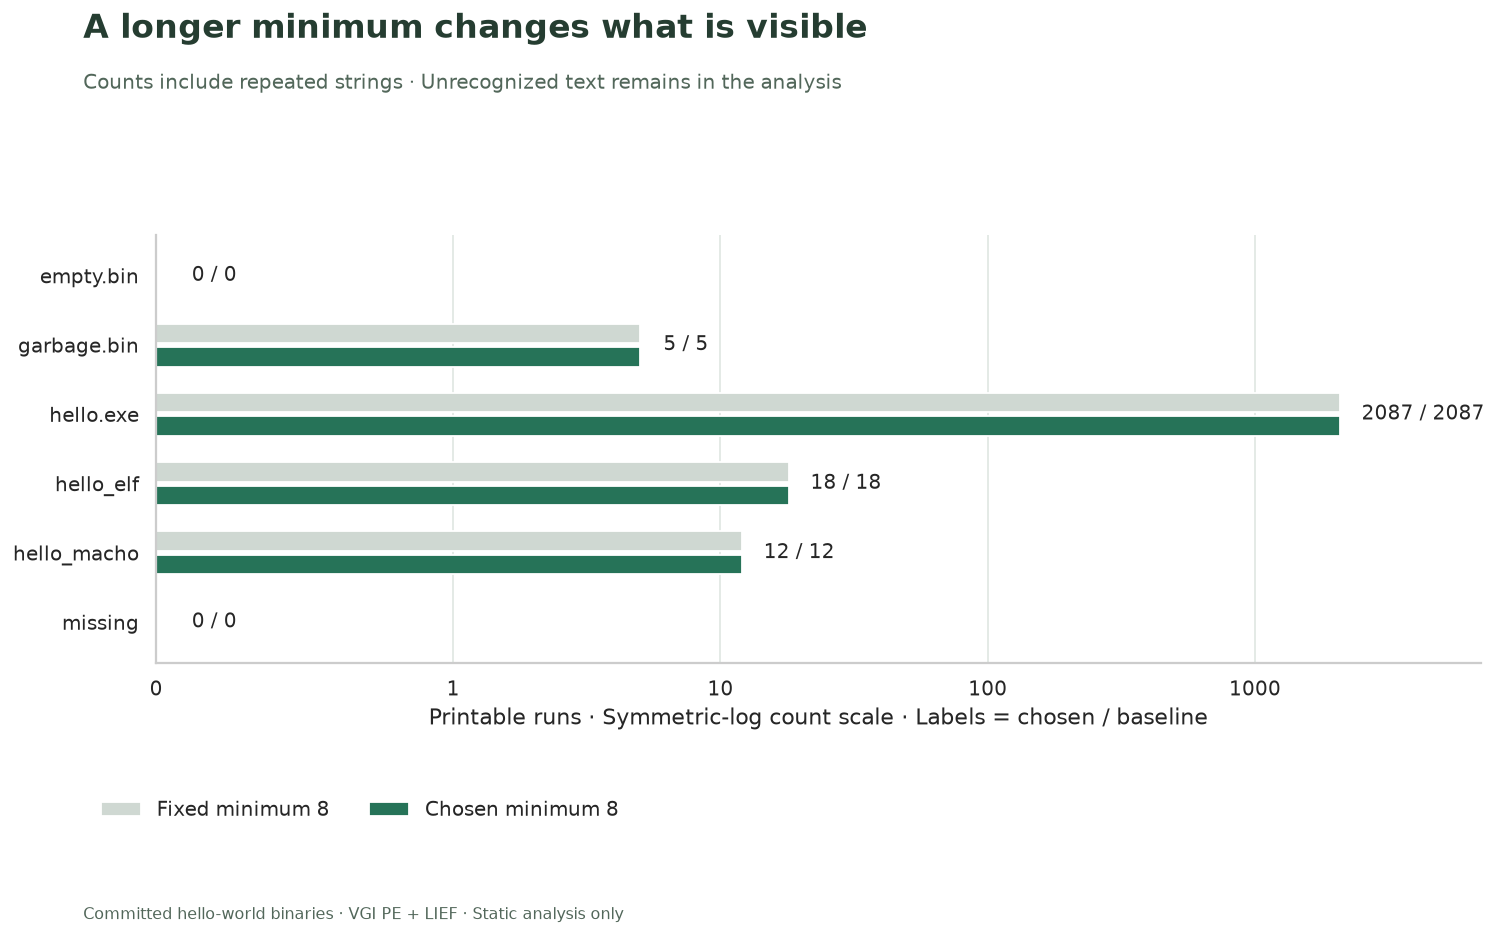

At minimum length **8**, **2,122 printable runs** remain from the **2,122** eight-character baseline. The known hello-world text remains visible at both demonstration settings. A smaller output is an extraction choice, not evidence that the underlying files changed.

,sample_id,format,baseline_runs,selected_runs,shortest_run,longest_run
0,empty.bin,None,0,0,<NA>,<NA>
1,garbage.bin,None,5,5,13,50
2,hello.exe,PE,2087,2087,8,104
3,hello_elf,ELF,18,18,8,41
4,hello_macho,MachO,12,12,9,41
5,missing,None,0,0,<NA>,<NA>


In [10]:
fig, ax = plt.subplots(figsize=(12, 7.3))
y = list(range(len(retention)))
ax.barh(
    [v - 0.17 for v in y],
    retention.baseline_runs,
    height=0.28,
    color="#cfd8d2",
    label="Fixed minimum 8",
)
ax.barh(
    [v + 0.17 for v in y],
    retention.selected_runs,
    height=0.28,
    color="#267358",
    label=f"Chosen minimum {MIN_STRING_LENGTH}",
)
for i, r in enumerate(retention.itertuples()):
    ax.text(
        max(r.baseline_runs, r.selected_runs) * 1.2 + 0.12,
        i,
        f"{r.selected_runs} / {r.baseline_runs}",
        va="center",
        fontsize=11,
    )
ax.set_yticks(y, retention.sample_id)
ax.invert_yaxis()
ax.set_xscale("symlog", linthresh=1)
ax.set_xlim(0, 7000)
ax.set_xticks([0, 1, 10, 100, 1000], [0, 1, 10, 100, 1000])
ax.grid(axis="y", visible=False)
ax.set_xlabel("Printable runs · Symmetric-log count scale · Labels = chosen / baseline")
fig.legend(loc="lower left", bbox_to_anchor=(0.08, 0.11), ncol=2, frameon=False)
finish(
    fig,
    "A longer minimum changes what is visible",
    "Counts include repeated strings · Unrecognized text remains in the analysis",
    "02_string_retention.png",
    bottom=0.20,
)
prose(
    f"At minimum length **{MIN_STRING_LENGTH}**, **{int(retention.selected_runs.sum()):,} printable runs** remain "
    f"from the **{int(retention.baseline_runs.sum()):,}** eight-character baseline. "
    "The known hello-world text remains visible at both demonstration settings. "
    "A smaller output is an extraction choice, not evidence that the underlying files changed."
)
display(retention)

## Check extraction semantics against the original bytes

The selected runs should equal the fixed baseline filtered by length, including
multiplicity, for these small fixtures. Their output is below the worker’s caps
(100,000 runs and 1,024 characters per run in the pinned source); this equivalence
is not promised for inputs that hit a cap. We also independently recompute whole-file
Shannon entropy from bytes, without running any executable.

In [11]:
%%sql checks <<
SELECT 'All six input records remain in the audit' AS check_name,
 (SELECT count(*)=6 FROM binary_audit) AS passed
UNION ALL SELECT 'Three recognized formats are retained',
 (SELECT count(format)=3 AND count(DISTINCT format)=3 FROM binary_audit)
UNION ALL SELECT 'Missing and empty inputs have distinct byte counts',
 (SELECT file_bytes IS NULL FROM binary_audit WHERE sample_id='missing')
 AND (SELECT file_bytes=0 FROM binary_audit WHERE sample_id='empty.bin')
UNION ALL SELECT 'Unrecognized text can still yield printable strings',
 (SELECT format IS NULL AND file_entropy IS NULL FROM binary_audit WHERE sample_id='garbage.bin')
 AND EXISTS(SELECT 1 FROM baseline_strings WHERE sample_id='garbage.bin')
UNION ALL SELECT 'Reported section counts match extracted rows',
 NOT EXISTS(SELECT 1 FROM binary_audit a WHERE format IS NOT NULL
 AND reported_sections<>(SELECT count(*) FROM section_rows s WHERE a.sample_id=s.sample_id))
UNION ALL SELECT 'Section extraction emits no rows for unrecognized or empty files',
 NOT EXISTS(SELECT 1 FROM section_rows WHERE sample_id IN ('garbage.bin','empty.bin'))
UNION ALL SELECT 'PE-only timestamp and import hash stay NULL for other formats',
 NOT EXISTS(SELECT 1 FROM binary_audit WHERE format IS DISTINCT FROM 'PE'
 AND (pe_header_timestamp IS NOT NULL OR pe_import_hash IS NOT NULL))
UNION ALL SELECT 'All selected runs meet the chosen minimum',
 NOT EXISTS(SELECT 1 FROM selected_strings WHERE length(value)<{{ MIN_STRING_LENGTH }})
UNION ALL SELECT 'Chosen extraction equals baseline length filtering with multiplicity',
 NOT EXISTS((SELECT sample_id,value FROM selected_strings EXCEPT ALL SELECT sample_id,value FROM baseline_strings WHERE length(value)>={{ MIN_STRING_LENGTH }})
 UNION ALL (SELECT sample_id,value FROM baseline_strings WHERE length(value)>={{ MIN_STRING_LENGTH }} EXCEPT ALL SELECT sample_id,value FROM selected_strings))
UNION ALL SELECT 'Known hello-world text appears in all executable fixtures at 8 or 16',
 {{ MIN_STRING_LENGTH }}>length('hello from vgi-pe static-analysis fixture') OR (SELECT count(DISTINCT sample_id)=3 FROM selected_strings WHERE value='hello from vgi-pe static-analysis fixture')
UNION ALL SELECT 'NULL binary bytes return no printable rows',
 (SELECT count(*)=0 FROM pe.main.strings(NULL::BLOB,min_len:=8))
UNION ALL SELECT 'Fixture outputs do not approach extraction caps',
 (SELECT max(n)<100000 FROM (SELECT count(*) n FROM baseline_strings GROUP BY sample_id))
 AND (SELECT max(length(value))<1024 FROM baseline_strings);

In [12]:
assert checks.passed.all(), checks.loc[~checks.passed].to_dict("records")
assert (
    int(retention.selected_runs.sum())
    == con.execute("SELECT count(*) FROM selected_strings").fetchone()[0]
)
for row in evidence.loc[evidence.format.notna()].itertuples():
    data = (Path("fixtures") / row.sample_id).read_bytes()
    counts = Counter(data)
    expected = -sum((n / len(data)) * math.log2(n / len(data)) for n in counts.values())
    assert abs(expected - row.file_entropy) < 1e-12
prose(
    f"**{len(checks)} SQL checks, printable-run reconciliation and three independent entropy calculations passed.** These validate extraction on the fixtures, not malware detection or signature trust."
)

**12 SQL checks, printable-run reconciliation and three independent entropy calculations passed.** These validate extraction on the fixtures, not malware detection or signature trust.

## Experiment · require longer printable runs

Change only `MIN_STRING_LENGTH` to **16**, restart, and run all. Predict which inputs
still produce strings. The file hashes, recognized formats, signature-presence
flags, header timestamp, section counts and entropy chart should remain identical.
The string output and counts should shrink, including for the unrecognized text.

The comparison shows a retrieval tradeoff: a longer minimum reduces output while
omitting short strings that may still be useful. It does not improve the trustworthiness
of a binary. Reset to `8` for the saved default.

In [13]:
con.close()
plt.close("all")

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/)